# NeuroSignal AI — Pipeline
## 0. Setup

In [7]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

from src import config
print(config.ROOT)
print("Raw data found:", config.RAW_DIR.exists())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
\\192.168.0.100\Shruti\ASHRUTI\Projects\neurosignal-ai
Raw data found: True


In [8]:
import warnings
warnings.filterwarnings("ignore", message="Channel names are not unique")

from src.labels import load_all_labels
labels = load_all_labels()
print(len(labels), "seizures,", labels["duration"].sum(), "seconds of seizure")
labels

22 seizures, 1574 seconds of seizure


,patient,file,start,end,duration
0,chb01,chb01_03.edf,2996,3036,40
1,chb01,chb01_04.edf,1467,1494,27
2,chb01,chb01_15.edf,1732,1772,40
3,chb01,chb01_16.edf,1015,1066,51
4,chb01,chb01_18.edf,1720,1810,90
5,chb01,chb01_21.edf,327,420,93
6,chb01,chb01_26.edf,1862,1963,101
7,chb02,chb02_16.edf,130,212,82
8,chb02,chb02_16+.edf,2972,3053,81
9,chb02,chb02_19.edf,3369,3378,9


In [9]:
import mne
total_seconds = sum(
    mne.io.read_raw_edf(f, preload=False, verbose=False).n_times / 256
    for f in config.RAW_DIR.glob("*.edf")
)
seizure_pct = labels["duration"].sum() / total_seconds * 100
print(f"Total: {total_seconds/3600:.2f} h | Seizure share: {seizure_pct:.2f}%")

Total: 28.91 h | Seizure share: 1.51%


## 2. Preprocessing check
Compare the power spectrum before and after the 0.5–40 Hz band-pass filter.
The 60 Hz mains spike should disappear. The figure is saved to `docs/` for the README.

21 channels: ['FP1-F7', 'F7-T7', 'T7-P7', 'P7-O1', 'FP1-F3', 'F3-C3', 'C3-P3', 'P3-O1', 'FP2-F4', 'F4-C4', 'C4-P4', 'P4-O2', 'FP2-F8', 'F8-T8', 'T8-P8', 'P8-O2', 'FZ-CZ', 'CZ-PZ', 'T7-FT9', 'FT9-FT10', 'FT10-T8']
Plotting power spectral density (dB=True).


C:\Users\Shruti\AppData\Local\Temp\ipykernel_23996\523165420.py:12: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  raw_before.compute_psd(fmax=80, verbose=False).plot(axes=axes[0], show=False)


Plotting power spectral density (dB=True).


C:\Users\Shruti\AppData\Local\Temp\ipykernel_23996\523165420.py:13: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  raw_after.compute_psd(fmax=80, verbose=False).plot(axes=axes[1], show=False)


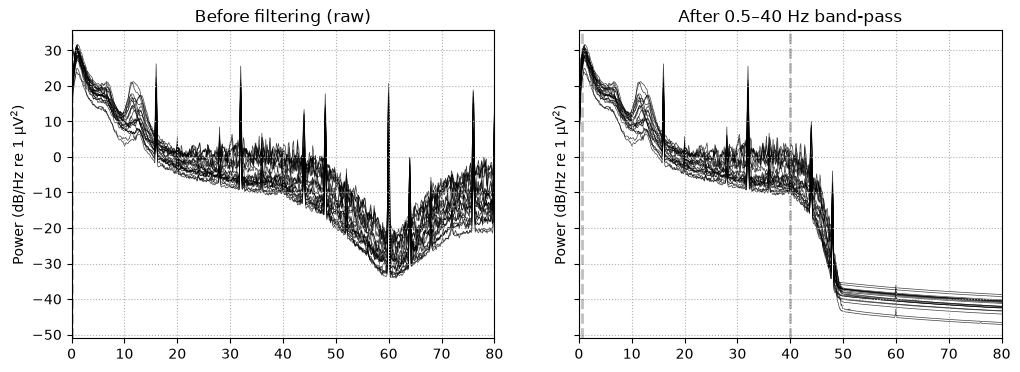

In [11]:
import mne
import matplotlib.pyplot as plt
from src.preprocess import load_raw

# Same file, raw versus cleaned
raw_before = mne.io.read_raw_edf(config.RAW_DIR / "chb01_03.edf", preload=True, verbose=False)
raw_after = load_raw("chb01_03.edf")
print(len(raw_after.ch_names), "channels:", raw_after.ch_names)  # expect 21

# Side-by-side power spectra, same y-axis for a fair comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
raw_before.compute_psd(fmax=80, verbose=False).plot(axes=axes[0], show=False)
raw_after.compute_psd(fmax=80, verbose=False).plot(axes=axes[1], show=False)
axes[0].set_title("Before filtering (raw)")
axes[1].set_title("After 0.5–40 Hz band-pass")

# Save as README evidence
fig.savefig(config.DOCS_DIR / "psd_before_after.png", dpi=120, bbox_inches="tight")
plt.show()

## 3. Windowing
Check that every file has all 21 channels, then cut one recording into 4-second windows.
Expected for chb01_03: 900 windows, 10 labelled as seizure (seizure 2996–3036 s).

In [12]:
# Confirm every file contains all 21 channels we use
missing = {}
for f in sorted(config.RAW_DIR.glob("*.edf")):
    names = mne.io.read_raw_edf(f, preload=False, verbose=False).ch_names
    names = ["T8-P8" if n == "T8-P8-0" else n for n in names]  # same rename as load_raw
    lacking = [c for c in config.CHANNELS if c not in names]
    if lacking:
        missing[f.name] = lacking
print("Files missing channels:", missing or "none")

Files missing channels: none


In [13]:
from src.preprocess import load_raw, make_windows

# Window one recording and check shapes and labels
raw = load_raw("chb01_03.edf")
windows, y, starts = make_windows(raw, "chb01_03.edf", labels)
print("Windows shape:", windows.shape)   # (windows, channels, samples)
print("Seizure windows:", y.sum(), "| seizure starts (s):", starts[y == 1])

Windows shape: (900, 21, 1024)
Seizure windows: 10 | seizure starts (s): [2996 3000 3004 3008 3012 3016 3020 3024 3028 3032]


## 4. Features
For every 4-second window and channel: log band power (delta, theta, alpha, beta) and log line length = 105 features.
All 30 files are processed one at a time and saved to `data/features/features.pkl`.

In [14]:
from src.features import build_feature_table

features = build_feature_table(labels)
n_seiz = features["label"].sum()
print(f"\n{len(features)} windows, {n_seiz} seizure windows ({n_seiz/len(features)*100:.2f}%)")
print("Feature columns:", features.shape[1] - 4)  # minus file, patient, start, label

chb01_01.edf: 900 windows, 0 seizure
chb01_02.edf: 900 windows, 0 seizure
chb01_03.edf: 900 windows, 10 seizure
chb01_04.edf: 900 windows, 7 seizure
chb01_15.edf: 900 windows, 10 seizure
chb01_16.edf: 900 windows, 13 seizure
chb01_18.edf: 900 windows, 23 seizure
chb01_21.edf: 900 windows, 23 seizure
chb01_26.edf: 581 windows, 26 seizure
chb02_01.edf: 900 windows, 0 seizure
chb02_02.edf: 900 windows, 0 seizure
chb02_16+.edf: 900 windows, 20 seizure
chb02_16.edf: 239 windows, 21 seizure
chb02_19.edf: 900 windows, 3 seizure
chb03_01.edf: 900 windows, 14 seizure
chb03_02.edf: 900 windows, 16 seizure
chb03_03.edf: 900 windows, 17 seizure
chb03_04.edf: 900 windows, 14 seizure
chb03_05.edf: 900 windows, 0 seizure
chb03_06.edf: 900 windows, 0 seizure
chb03_34.edf: 900 windows, 12 seizure
chb03_35.edf: 900 windows, 16 seizure
chb03_36.edf: 900 windows, 14 seizure
chb05_01.edf: 902 windows, 0 seizure
chb05_02.edf: 900 windows, 0 seizure
chb05_06.edf: 900 windows, 29 seizure
chb05_13.edf: 900 win

### Do the features separate seizure from normal windows?
Average each feature type across channels and compare the two groups. Saved to `docs/` as README evidence.

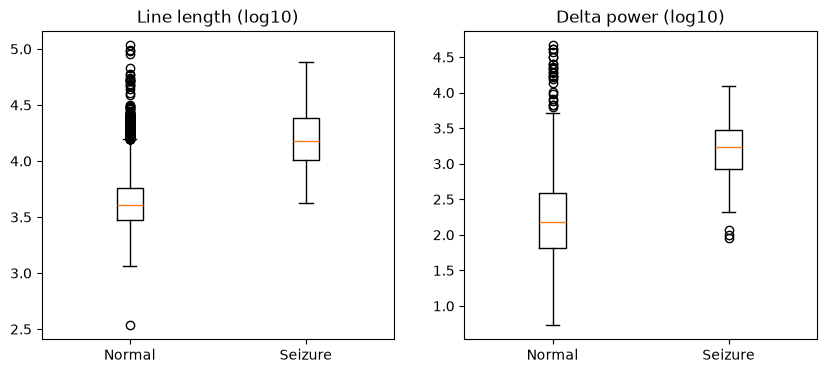

In [15]:
# Compare normal vs seizure windows for two feature types (averaged across channels)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, prefix, title in zip(axes, ["linelen_", "delta_"], ["Line length (log10)", "Delta power (log10)"]):
    values = features.filter(like=prefix).mean(axis=1)
    ax.boxplot([values[features["label"] == 0], values[features["label"] == 1]],
               tick_labels=["Normal", "Seizure"])
    ax.set_title(title)
fig.savefig(config.DOCS_DIR / "features_seizure_vs_normal.png", dpi=120, bbox_inches="tight")
plt.show()

## 5. Training and patient-held-out evaluation
LightGBM, trained 4 times: each time on 3 patients and tested on the unseen 4th (leave-one-patient-out).
Every window gets a probability from a model that never saw that patient.

In [16]:
from src.model import cross_validate, window_metrics, fit_final_model

# Train on 3 patients, test on the 4th, for each patient in turn
pred_patient = cross_validate(features, split="patient")
metrics_patient = window_metrics(pred_patient)
metrics_patient

,patient,sensitivity,precision,f1,auroc
0,All,0.396,0.090,0.147,0.899
1,chb01,0.170,0.864,0.284,0.983
2,chb02,0.545,0.421,0.475,0.967
3,chb03,0.194,0.769,0.310,0.970
4,chb05,0.679,0.058,0.106,0.788


### Patient split vs random split
The same model with a random split (windows from every patient in both train and test).
The gap shows how much patient leakage inflates the scores.

In [18]:
import pandas as pd
# Leaky evaluation for comparison
pred_random = cross_validate(features, split="random")
metrics_random = window_metrics(pred_random)

comparison = pd.DataFrame({
    "Patient-held-out (honest)": metrics_patient.iloc[0, 1:],
    "Random split (leaky)": metrics_random.iloc[0, 1:],
})
comparison

,Patient-held-out (honest),Random split (leaky)
sensitivity,0.396,0.91
precision,0.09,0.926
f1,0.147,0.918
auroc,0.899,0.997


### Feature importance
Which features the model relied on most (trained on all patients). Saved to `docs/`.

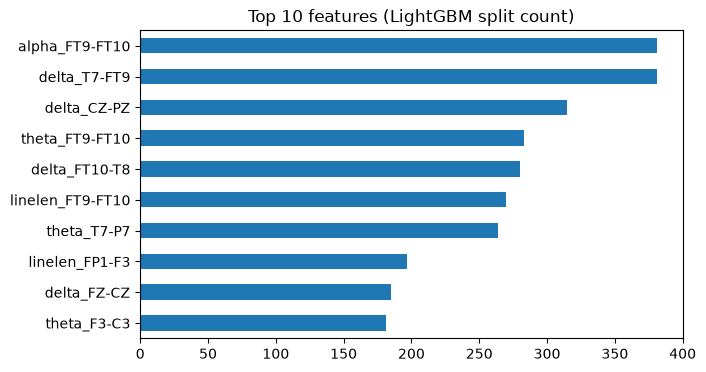

In [19]:
from src.features import feature_names

final_model = fit_final_model(features)
importance = pd.Series(final_model.feature_importances_, index=feature_names())
top = importance.sort_values().tail(10)   # 10 most-used features

fig, ax = plt.subplots(figsize=(7, 4))
top.plot.barh(ax=ax)
ax.set_title("Top 10 features (LightGBM split count)")
fig.savefig(config.DOCS_DIR / "feature_importance.png", dpi=120, bbox_inches="tight")
plt.show()

## 6. Event-level evaluation
Alarm = at least 2 consecutive windows (8 s) above the threshold.
A seizure is detected if any alarm overlaps it; alarms overlapping no seizure are false alarms.
Several thresholds are shown as a sensitivity vs false-alarm trade-off (patient-held-out predictions).

In [20]:
from src.events import evaluate_events

# Event-level results at several thresholds (honest, patient-held-out predictions)
rows = [evaluate_events(pred_patient, labels, t)[0] for t in [0.1, 0.3, 0.5, 0.7]]
tradeoff = pd.DataFrame(rows)
tradeoff

,threshold,seizures_detected,sensitivity,false_alarms,false_alarms_per_hour,median_latency_s
0,0.1,14/22,0.636,307,10.62,17.5
1,0.3,12/22,0.545,283,9.79,21.0
2,0.5,11/22,0.500,263,9.10,20.0
3,0.7,11/22,0.500,255,8.82,20.0


In [21]:
# Per-patient detail at threshold 0.3 (change after seeing the trade-off table)
summary, per_patient = evaluate_events(pred_patient, labels, 0.3)
print(summary)
per_patient

{'threshold': 0.3, 'seizures_detected': '12/22', 'sensitivity': 0.545, 'false_alarms': 283, 'false_alarms_per_hour': 9.79, 'median_latency_s': 21.0}


,seizures,detected,false_alarms
chb01,7,1,0
chb02,3,2,6
chb03,7,4,1
chb05,5,5,276


## 7. Calibration and the review flag
Are the probabilities honest? Reliability diagram and ECE before and after Platt calibration
(learned on training patients only). Windows with probability 0.3–0.7 are flagged "needs expert review".

ECE before: 0.066 | after calibration: 0.038


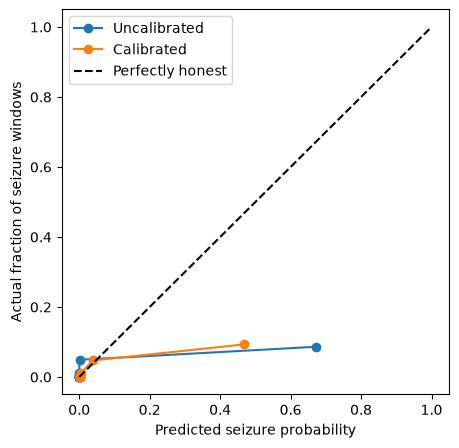

In [22]:
from sklearn.calibration import calibration_curve
from src.model import expected_calibration_error

# Calibrated version of the honest, patient-held-out predictions
pred_cal = cross_validate(features, split="patient", calibrate=True)

y = pred_patient["label"]
ece_before = expected_calibration_error(y, pred_patient["prob"])
ece_after = expected_calibration_error(y, pred_cal["prob"])
print(f"ECE before: {ece_before:.3f} | after calibration: {ece_after:.3f}")

# Reliability diagram: predicted probability vs actual seizure rate
fig, ax = plt.subplots(figsize=(5, 5))
for name, p in [("Uncalibrated", pred_patient["prob"]), ("Calibrated", pred_cal["prob"])]:
    frac_pos, mean_pred = calibration_curve(y, p, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=name)
ax.plot([0, 1], [0, 1], "k--", label="Perfectly honest")
ax.set_xlabel("Predicted seizure probability")
ax.set_ylabel("Actual fraction of seizure windows")
ax.legend()
fig.savefig(config.DOCS_DIR / "reliability_diagram.png", dpi=120, bbox_inches="tight")
plt.show()

In [23]:
# Event-level results with calibrated probabilities
rows = [evaluate_events(pred_cal, labels, t)[0] for t in [0.1, 0.3, 0.5]]
display(pd.DataFrame(rows))

# "Needs expert review" band: uncertain windows go to a human
review = pred_cal["prob"].between(0.3, 0.7)
print(f"Windows flagged for review: {review.sum()} ({review.mean()*100:.2f}% of all)")
print(f"Seizure windows inside the review band: {(review & (pred_cal['label']==1)).sum()} of {pred_cal['label'].sum()}")

,threshold,seizures_detected,sensitivity,false_alarms,false_alarms_per_hour,median_latency_s
0,0.1,17/22,0.773,407,14.08,16.0
1,0.3,15/22,0.682,248,8.58,18.0
2,0.5,10/22,0.455,166,5.74,17.0


Windows flagged for review: 1201 (4.62% of all)
Seizure windows inside the review band: 119 of 399


## 8. Error analysis (false negatives and false positives)
Using calibrated probabilities at threshold 0.3: which seizures were missed and why,
and where the false alarms come from.

In [24]:
from src.events import seizure_outcomes, false_alarm_list

THRESHOLD = 0.3
outcomes = seizure_outcomes(pred_cal, labels, THRESHOLD)

# Missed seizures first, lowest model confidence first
display(outcomes.sort_values(["detected", "max_prob"]))

# Are missed seizures shorter than detected ones?
print(outcomes.groupby("detected")["duration_s"].median().rename("median duration (s)"))

,patient,file,duration_s,detected,max_prob
2,chb01,chb01_15.edf,40,False,0.077
1,chb01,chb01_04.edf,27,False,0.148
4,chb01,chb01_18.edf,90,False,0.152
3,chb01,chb01_16.edf,51,False,0.159
0,chb01,chb01_03.edf,40,False,0.165
5,chb01,chb01_21.edf,93,False,0.298
9,chb02,chb02_19.edf,9,False,0.410
11,chb03,chb03_02.edf,65,True,0.351
13,chb03,chb03_04.edf,52,True,0.353
10,chb03,chb03_01.edf,52,True,0.381


detected
False    40.0
True     81.0
Name: median duration (s), dtype: float64


In [25]:
false_alarms = false_alarm_list(pred_cal, labels, THRESHOLD)
print(f"{len(false_alarms)} false alarms")

# By patient, and the files producing the most
display(false_alarms.groupby("patient").size().rename("false alarms"))
display(false_alarms.groupby("file").size().sort_values(ascending=False).head(5).rename("false alarms"))
print("Median false-alarm duration (s):", false_alarms["duration_s"].median())

248 false alarms


patient
chb02     21
chb03     22
chb05    205
Name: false alarms, dtype: int64

file
chb05_02.edf    45
chb05_22.edf    44
chb05_17.edf    43
chb05_01.edf    23
chb05_16.edf    20
Name: false alarms, dtype: int64

Median false-alarm duration (s): 12.0


### What does a false alarm look like?
Raw EEG of chb05's longest false alarm next to one of chb05's real seizures (same patient, 4 channels).

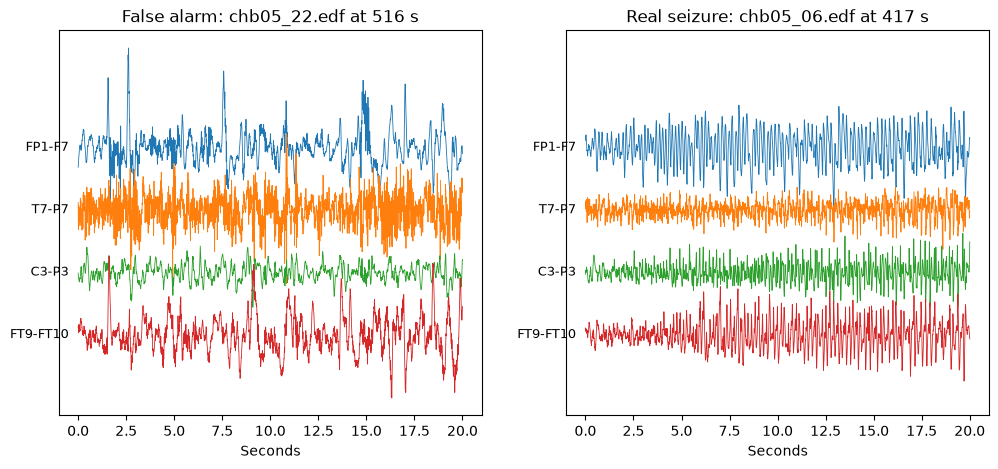

In [27]:
import numpy as np
# Longest chb05 false alarm vs a real chb05 seizure
fa = false_alarms[false_alarms["patient"] == "chb05"].sort_values("duration_s").iloc[-1]
sz = labels[labels["file"] == "chb05_06.edf"].iloc[0]
show = ["FP1-F7", "T7-P7", "C3-P3", "FT9-FT10"]   # 4 channels from different regions

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, (fname, t0, title) in zip(axes, [
        (fa["file"], fa["start_s"], f"False alarm: {fa['file']} at {fa['start_s']} s"),
        (sz["file"], sz["start"], f"Real seizure: {sz['file']} at {sz['start']} s")]):
    raw = load_raw(fname)
    clip = raw.copy().crop(t0, t0 + 20).get_data(picks=show) * 1e6   # 20 s, microvolts
    t = np.arange(clip.shape[1]) / 256
    for i, ch in enumerate(show):
        ax.plot(t, clip[i] - i * 400, linewidth=0.6)                   # offset each channel
        ax.text(-0.5, -i * 400, ch, ha="right", va="center", fontsize=9)
    ax.set_title(title)
    ax.set_xlabel("Seconds")
    ax.set_yticks([])
fig.savefig(config.DOCS_DIR / "false_alarm_vs_seizure.png", dpi=120, bbox_inches="tight")
plt.show()

## 9. Demo figure and sample clips
Export 4 short clips (EEG + honest out-of-fold probabilities) to `data/sample/` for the app,
and draw the challenge's demo flow: waveform → spectrogram → probability timeline with highlighted events.

In [29]:
from src.demo import export_clip, load_clip, demo_figure

# (name, file, clip start s, clip length s): chosen around known events
clips = [
    ("detected_chb05_06", "chb05_06.edf", 360, 240),
    ("detected_chb03_01", "chb03_01.edf", 300, 180),
    ("missed_chb01_03", "chb01_03.edf", 2940, 180),
    ("false_alarm_chb05_22", "chb05_22.edf", 456, 180),
]
for name, file_name, t0, duration in clips:
    export_clip(name, file_name, t0, duration, pred_cal, labels)
    print("Saved", name)

Saved detected_chb05_06
Saved detected_chb03_01
Saved missed_chb01_03
Saved false_alarm_chb05_22


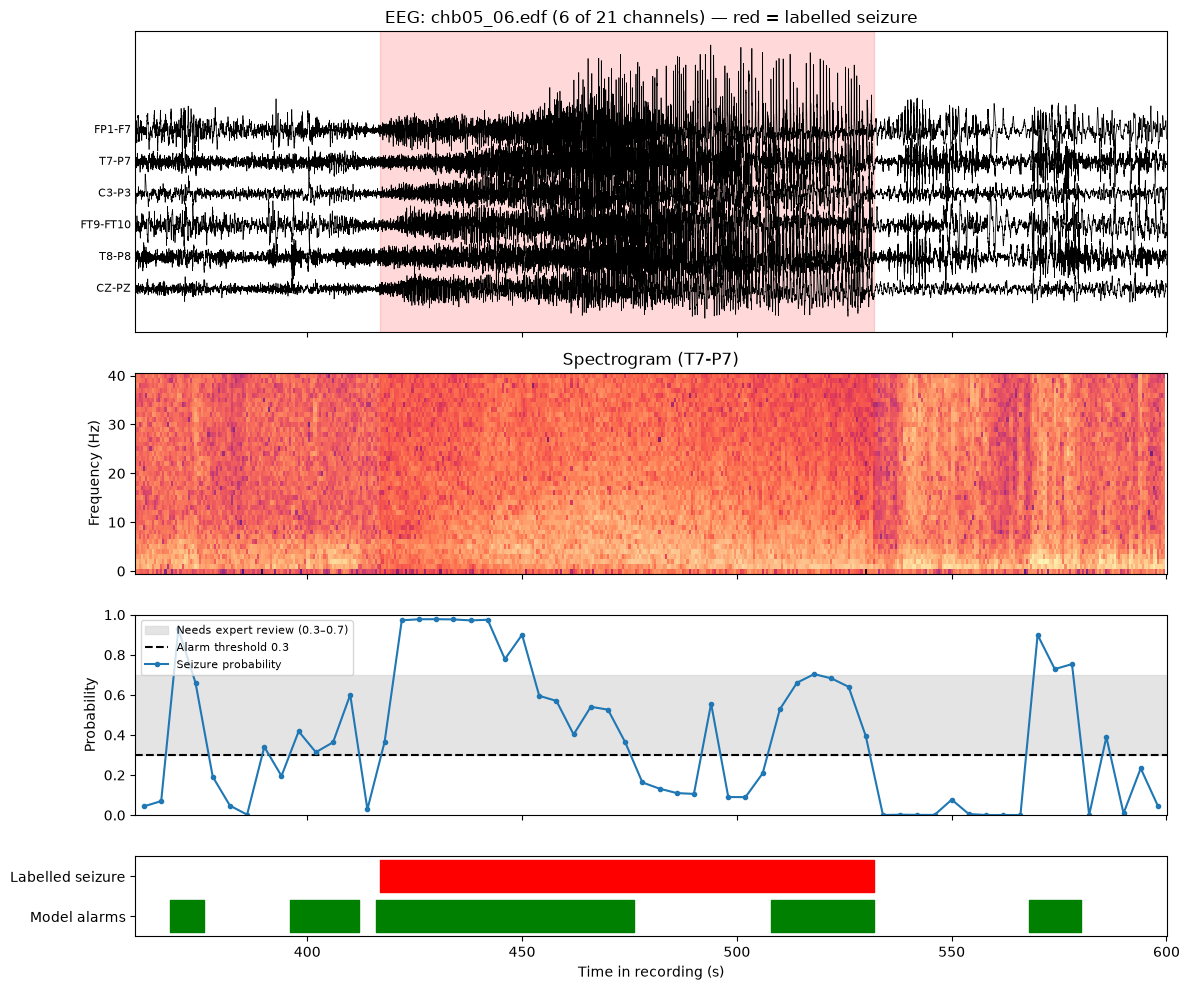

In [33]:
clip = load_clip(config.SAMPLE_DIR / "detected_chb05_06.npz")
fig = demo_figure(clip, threshold=0.3)
fig.savefig(config.DOCS_DIR / "demo_timeline.png", dpi=120, bbox_inches="tight")
plt.show()